### Import Libraries & Load Dataset

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

DATA_PATH = Path("data/Online Retail.xlsx")

df = pd.read_excel(DATA_PATH)

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (541909, 8)

First 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


### Data Understanding

In [4]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nUnique Customers:", df["CustomerID"].nunique())

print("\nUnique Countries:", df["Country"].nunique())

Dataset Shape: (541909, 8)

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows: 5268

Statistical Summary:


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303



Unique Customers: 4372

Unique Countries: 38


### 2. Data Cleaning and Preprocessing

In [5]:

df_clean = df.copy()


df_clean = df_clean.drop_duplicates()


df_clean = df_clean.dropna(subset=["CustomerID"])

df_clean = df_clean[~df_clean["InvoiceNo"].astype(str).str.startswith("C")]

df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)

df_clean["TotalAmount"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:", df_clean.duplicated().sum())

print("\nUnique Customers:", df_clean["CustomerID"].nunique())

Original Shape: (541909, 8)
Cleaned Shape: (392692, 9)

Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalAmount    0
dtype: int64

Duplicate Rows: 0

Unique Customers: 4338


### RFM Analysis

In [6]:

reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)


rfm = df_clean.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalAmount": "sum"
})

rfm.columns = ["Recency", "Frequency", "Monetary"]

print("RFM Dataset Shape:", rfm.shape)

display(rfm.head(10))

print("\nRFM Statistical Summary:")
display(rfm.describe())

RFM Dataset Shape: (4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40
12352,36,8,2506.04
12353,204,1,89.00
12354,232,1,1079.40
12355,214,1,459.40



RFM Statistical Summary:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


### 3. Feature Preparation and Standardization

In [7]:
from sklearn.preprocessing import StandardScaler

rfm_log = np.log1p(rfm)

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=rfm.columns,
    index=rfm.index
)

print("Scaled Dataset Shape:", rfm_scaled_df.shape)

print("\nScaled Data Preview:")
display(rfm_scaled_df.head())

print("\nScaled Features Summary:")
display(rfm_scaled_df.describe().round(2))

Scaled Dataset Shape: (4338, 3)

Scaled Data Preview:


,Recency,Frequency,Monetary
CustomerID,,,
12346,1.461993,-0.955214,3.707716
12347,-2.038734,1.074425,1.414903
12348,0.373104,0.386304,0.720024
12349,-0.623086,-0.955214,0.702287
12350,1.424558,-0.955214,-0.614514



Scaled Features Summary:


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-2.34,-0.96,-4.00
25%,-0.66,-0.96,-0.68
50%,0.09,-0.36,-0.07
75%,0.84,0.65,0.66
max,1.56,5.86,4.73


### PCA – Principal Component Analysis

In [8]:
from sklearn.decomposition import PCA


pca = PCA(n_components=2)

rfm_pca = pca.fit_transform(rfm_scaled_df)

pca_df = pd.DataFrame(
    rfm_pca,
    columns=["PC1", "PC2"],
    index=rfm.index
)

print("PCA Dataset Shape:", pca_df.shape)

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(pca.explained_variance_ratio_.sum())

display(pca_df.head())

PCA Dataset Shape: (4338, 2)

Explained Variance Ratio:
[0.75078634 0.18786648]

Total Explained Variance:
0.9386528181989527


,PC1,PC2
CustomerID,,
12346,0.873338,2.691611
12347,2.551874,-0.802858
12348,0.477339,0.747867
12349,0.147609,-0.457066
12350,-1.686255,0.679035


### Visualization

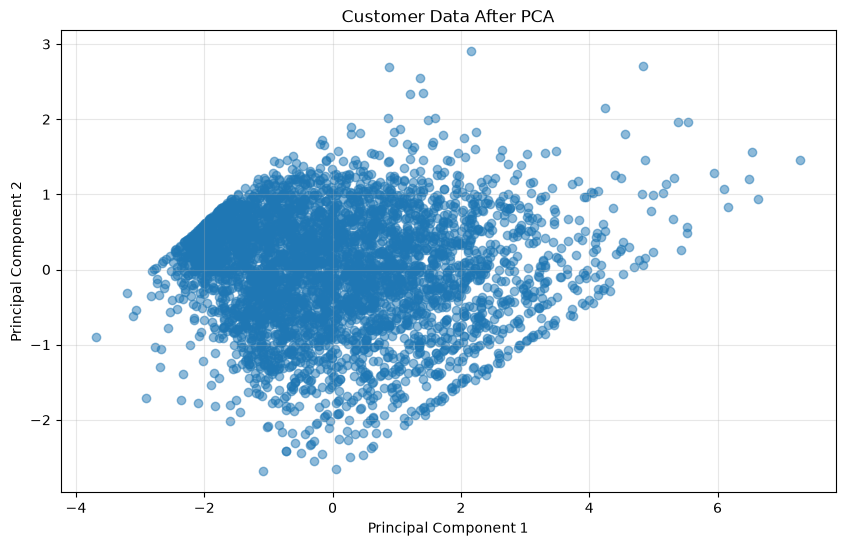

In [9]:
plt.figure(figsize=(10, 6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    alpha=0.5
)

plt.title("Customer Data After PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(alpha=0.3)
plt.show()

### 4. Optimal Number of Clusters - Elbow Method

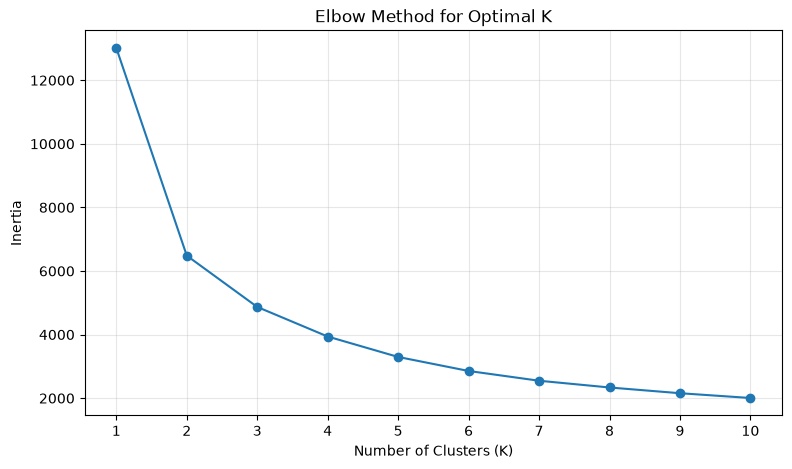

In [10]:
from sklearn.cluster import KMeans

inertia_values = []

K = range(1, 11)

for k in K:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(rfm_scaled_df)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(K, inertia_values, marker="o")

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(K)
plt.grid(alpha=0.3)
plt.show()

In [11]:
for k, inertia in zip(K, inertia_values):
    print(f"K = {k} | Inertia = {inertia:.2f}")

K = 1 | Inertia = 13014.00
K = 2 | Inertia = 6483.59
K = 3 | Inertia = 4869.49
K = 4 | Inertia = 3939.05
K = 5 | Inertia = 3296.71
K = 6 | Inertia = 2855.76
K = 7 | Inertia = 2548.82
K = 8 | Inertia = 2336.34
K = 9 | Inertia = 2156.01
K = 10 | Inertia = 2005.75


### K-Means Clustering

In [12]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled_df)

print("Cluster Distribution:")
print(rfm["Cluster"].value_counts().sort_index())

cluster_summary = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)

display(cluster_summary)

Cluster Distribution:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


,Recency,Frequency,Monetary
Cluster,,,
0,12.17,13.75,8088.02
1,181.51,1.32,341.00
2,17.70,2.19,557.32
3,71.64,4.08,1801.78


##  Final Visualization

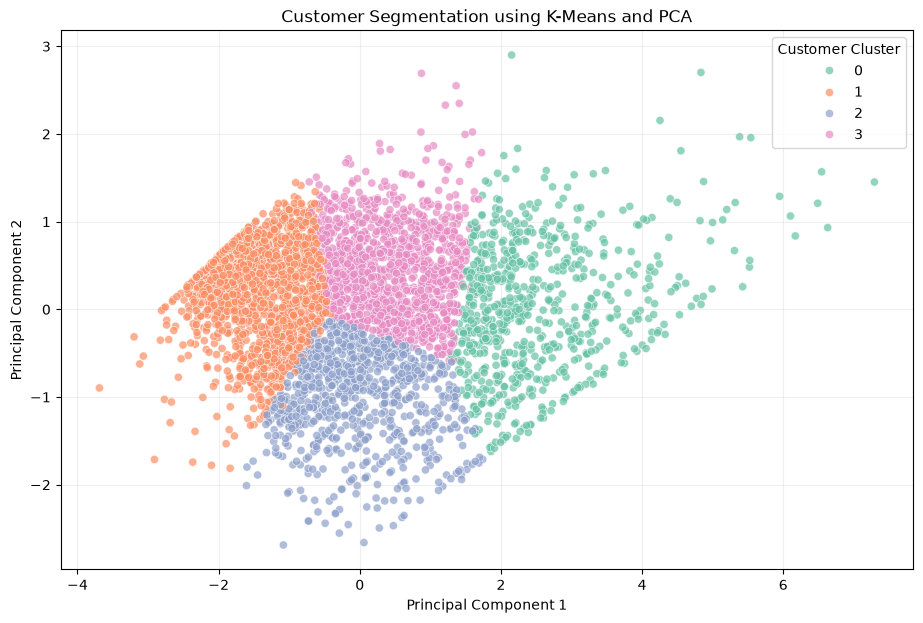

In [13]:
pca_df["Cluster"] = rfm["Cluster"]

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    alpha=0.7,
    s=35
)

plt.title("Customer Segmentation using K-Means and PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Cluster")
plt.grid(alpha=0.2)
plt.show()

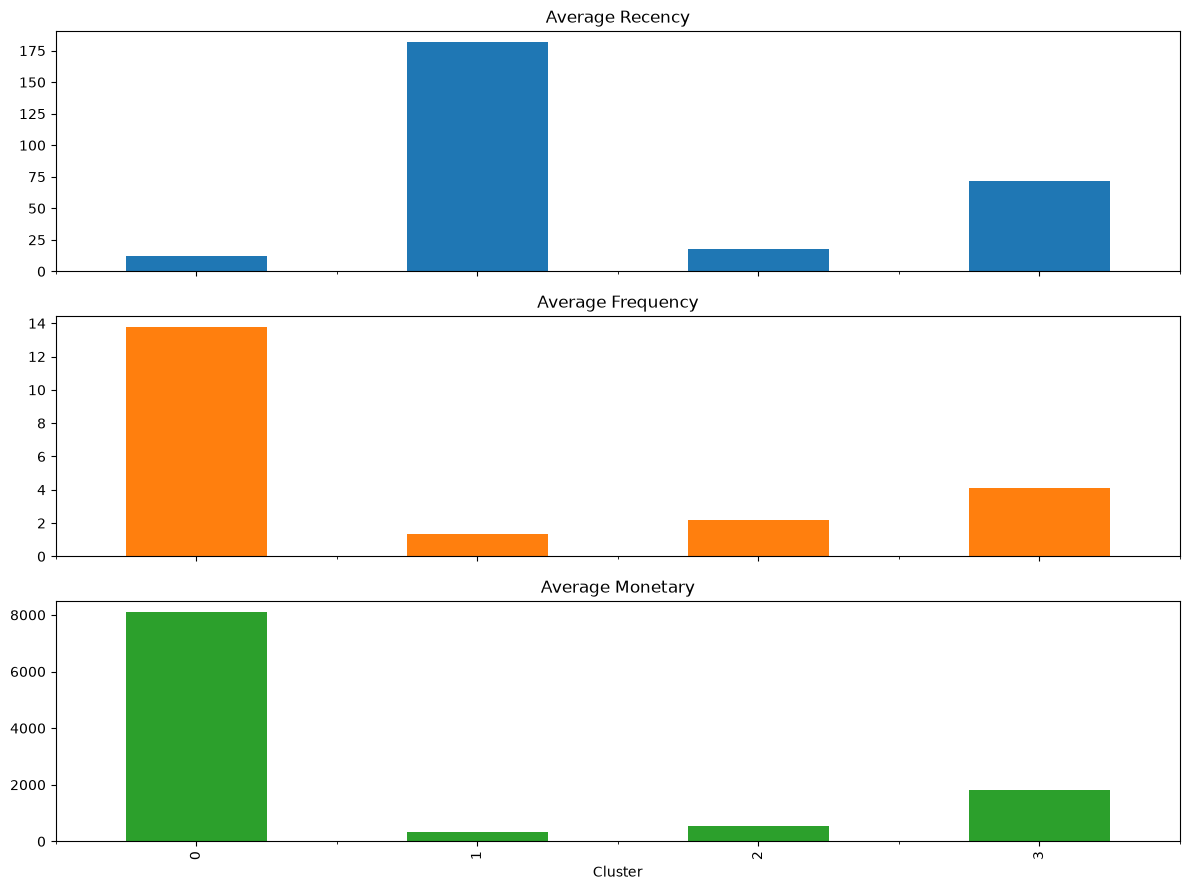

In [14]:
cluster_summary.plot(
    kind="bar",
    subplots=True,
    figsize=(12, 9),
    layout=(3, 1),
    legend=False,
    title=["Average Recency", "Average Frequency", "Average Monetary"]
)

plt.tight_layout()
plt.show()

### Customer Segmentation Insights

In [15]:
segment_names = {
    0: "High-Value Loyal Customers",
    1: "At-Risk / Inactive Customers",
    2: "Recent Low-Spending Customers",
    3: "Regular Customers"
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)

final_summary = rfm.groupby("Segment").agg(
    Customers=("Recency", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

display(final_summary)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Segment,,,,
At-Risk / Inactive Customers,1622,181.51,1.32,341.00
High-Value Loyal Customers,713,12.17,13.75,8088.02
Recent Low-Spending Customers,837,17.70,2.19,557.32
Regular Customers,1166,71.64,4.08,1801.78


### Export Results

In [16]:
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

rfm.to_csv(
    OUTPUT_DIR / "customer_segments.csv",
    encoding="utf-8-sig"
)

final_summary.to_csv(
    OUTPUT_DIR / "cluster_summary.csv",
    encoding="utf-8-sig"
)

pca_df.to_csv(
    OUTPUT_DIR / "pca_results.csv",
    encoding="utf-8-sig"
)

print("All outputs exported successfully!")
print("Exported files:", list(OUTPUT_DIR.iterdir()))

All outputs exported successfully!
Exported files: [WindowsPath('outputs/cluster_summary.csv'), WindowsPath('outputs/customer_segments.csv'), WindowsPath('outputs/pca_results.csv')]


## Final Validation

In [17]:
print("Total Customers:", len(rfm))

print("Unique Customers:", rfm.index.nunique())

print("\nCluster Counts:")
print(rfm["Cluster"].value_counts().sort_index())

print("\nMissing Values:")
print(rfm.isnull().sum())

print("\nPCA Shape:", pca_df.shape)

print("\nTotal Customers Across Clusters:",
      rfm["Cluster"].value_counts().sum())

print("\nAll Segmentation Checks Completed!")

Total Customers: 4338
Unique Customers: 4338

Cluster Counts:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64

Missing Values:
Recency      0
Frequency    0
Monetary     0
Cluster      0
Segment      0
dtype: int64

PCA Shape: (4338, 3)

Total Customers Across Clusters: 4338

All Segmentation Checks Completed!
